# Pipeline B — Municipal Concentration and Sector Specialization

**Question:** How unevenly are reported investment-related values distributed across Kosovo's municipalities, which municipalities dominate, and in which sectors does each municipality specialize?

We use the validated Common Dataset for 2019–2026. Each record is a monthly municipality–sector–registration-status group. The six monetary categories are analysed separately; they are not combined into one investment total.

The workflow is: **aggregate → municipal shares and HHI → sector specialization (LQ) → descriptive features → sampling sensitivity → interpretation.**

**Run first** (from the project root):

```
python -m phase_1.run_common_preprocessing
python -m phase_1.pipeline_b.run_pipeline_b
```

This notebook only reads and explains the saved outputs.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image
root=next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'phase_1/pipeline_b/run_pipeline_b.py').exists())
sys.path.insert(0,str(root))
from src.io_utils import COMMON, digest
from src.schema import MONEY
from phase_1.pipeline_b import MEASURE_LABELS
status=json.loads((root/'outputs/pipeline_b_validation.json').read_text(encoding='utf-8'))
assert status['status']=='PASS' and status['input_sha256']==digest(COMMON)
for relative,sha in status['output_hashes'].items():
    assert digest(root/relative)==sha

def table(name):
    return pd.read_csv(root/'outputs/tables/pipeline_b'/f'{name}.csv',keep_default_na=True)

def figure(name):
    display(Image(filename=str(root/'outputs/figures/pipeline_b'/name),width=1200))

MEASURE=MONEY[4]
YEAR=status['latest_complete_year']
print('Focus measure:',MEASURE_LABELS[MEASURE],'| Complete reporting year used in figures:',YEAR)
print('Records:',status['records'],'| Municipalities:',status['municipalities'])
display(pd.DataFrame({'measure':MONEY,'meaning':[MEASURE_LABELS[m] for m in MONEY]}))

Focus measure: Domestic investment purchases: 18% | Complete reporting year used in figures: 2025
Records: 124262 | Municipalities: 38


,measure,meaning
0,investment_purchases_imports_without_vat,Purchases/imports without VAT
1,investment_purchases_imports_nondeductible_vat,Purchases/imports: non-deductible VAT
2,investment_imports_18pct,Investment imports: 18%
3,investment_imports_8pct,Investment imports: 8%
4,domestic_investment_purchases_18pct,Domestic investment purchases: 18%
5,domestic_investment_purchases_8pct,Domestic investment purchases: 8%


## 1. Data and Aggregation

We select year, month, municipality, sector and the six monetary measures, then aggregate by municipality, sector and municipality–sector.

- **Reported:** all supplied months; 2019–2025 are full years and 2026 covers January–June.
- **January–June:** the same six months in every year for comparable periods. The two views overlap and must not be added together.

The aggregates preserve the reported totals for each monetary category.

In [2]:
municipal=table('municipal')
concentration=table('concentration')
sectors=table('sectors')
lq=table('specialization')
coverage=table('sector_coverage')
profiles=table('profiles')
focus=municipal.query('window == "reported" and year == @YEAR and measure == @MEASURE')

display(focus[['municipality','value','municipal_share']].head(5).style.format(
    {'value':'{:,.2f}','municipal_share':'{:.2%}'}))
display(sectors.query('window == "reported" and year == @YEAR and measure == @MEASURE')
    .nlargest(5,'value')[['primary_sector','value']].style.format({'value':'{:,.2f}'}))

,municipality,value,municipal_share
1520,PRISHTINË,"424,572,720.35",46.83%
1521,FERIZAJ,"58,036,031.93",6.40%
1522,GRAÇANICË,"54,955,934.07",6.06%
1523,PEJË,"44,597,337.67",4.92%
1524,PRIZREN,"41,787,505.56",4.61%


,primary_sector,value
907,Tregtia me shumice dhe pakice; Riparimi i mjeteve motorike dhe motoeikletave,"226,839,999.16"
900,Industria perpunuese,"160,464,699.27"
903,Ndertimtaria,"144,517,456.46"
889,Aktivitetet e patundshmerise,"79,884,808.97"
897,"Furnizimi me rryme, gaz, avull dhe ajer te kondicionuar","57,251,553.29"


## 2. Municipal Share and Pareto Analysis

$$
s_m=\frac{V_m}{\sum_j V_j}
$$

Municipal share measures each municipality's contribution to the national reported amount for the same category and period. Pareto analysis ranks municipalities and identifies how many are needed to reach 80% of that amount.

The maps use one colour scale across all six measures. Static figures show the latest complete year, 2025. These are reported-value shares, without population adjustment.

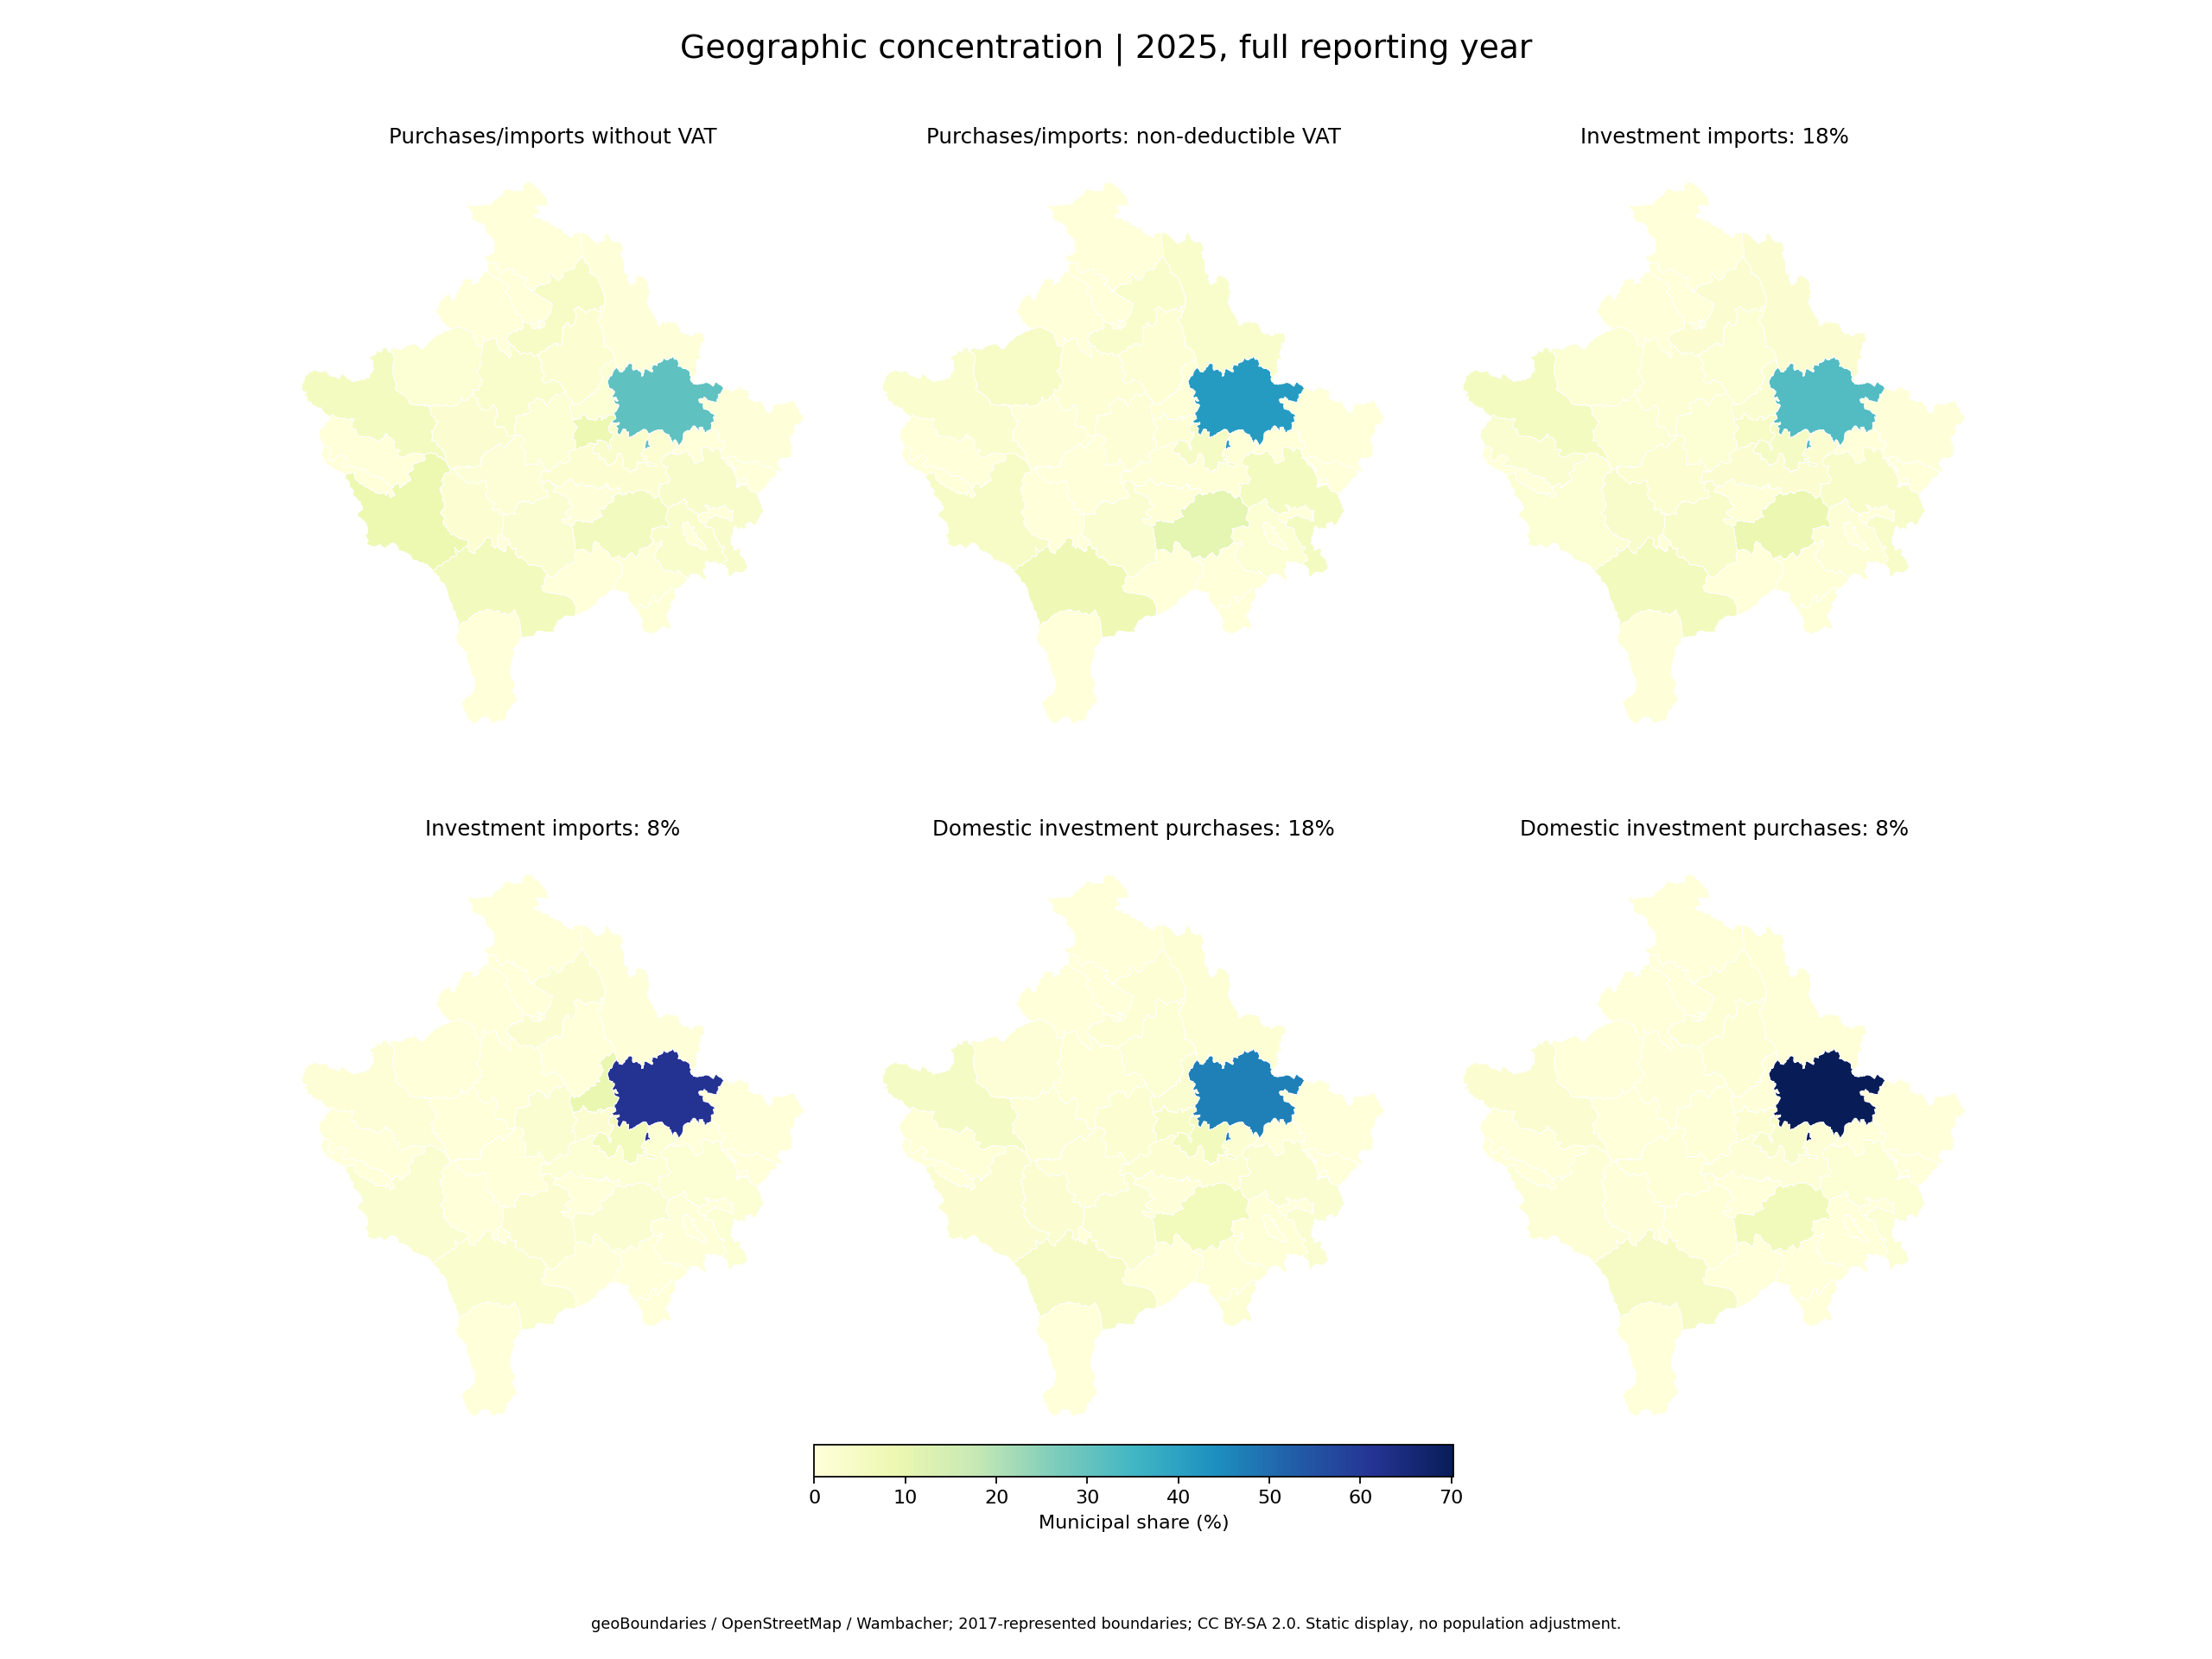

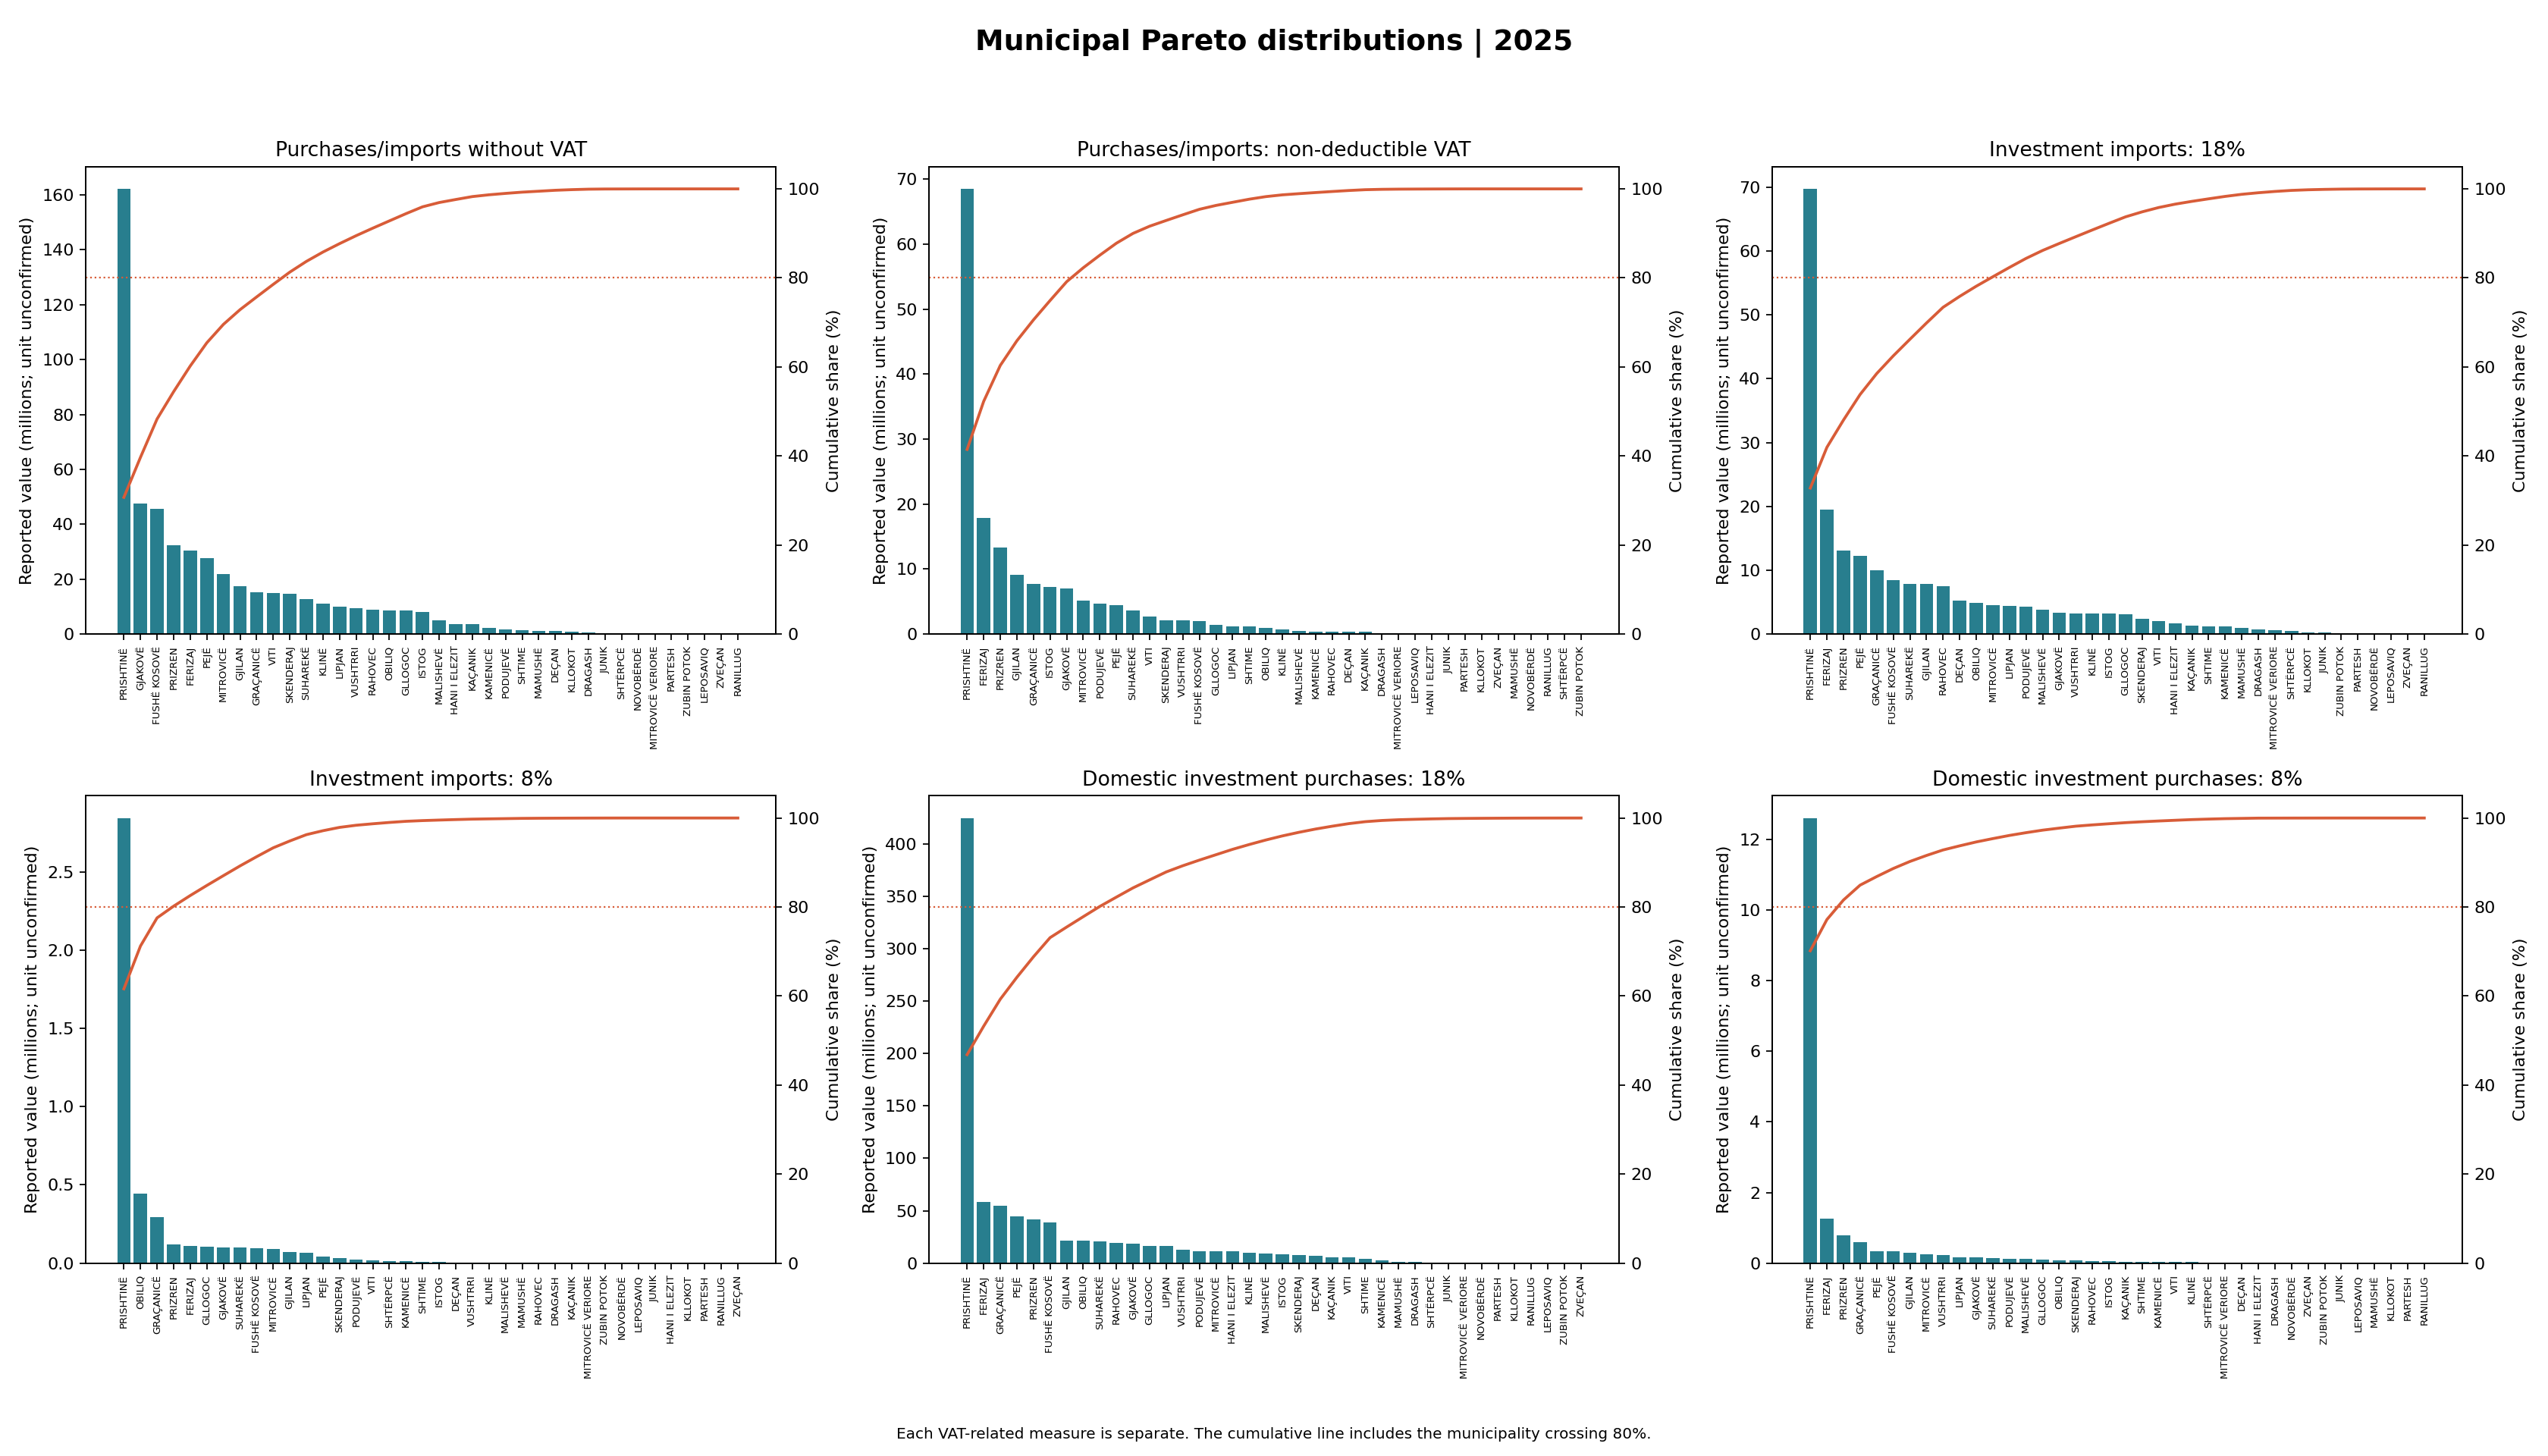

,measure,hhi,top1_share,top5_share,municipalities_for_80pct
36,Purchases/imports without VAT,0.1277,30.70%,60.21%,11
37,Purchases/imports: non-deductible VAT,0.2030,41.46%,70.57%,8
38,Investment imports: 18%,0.1350,32.79%,58.50%,12
39,Investment imports: 8%,0.3971,61.62%,82.58%,4
40,Domestic investment purchases: 18%,0.2378,46.83%,68.82%,9
41,Domestic investment purchases: 8%,0.5021,70.17%,86.84%,3


Leading municipalities across the six measures: PRISHTINË


In [3]:
figure('01_geographic_share.png')
figure('02_municipal_pareto.png')
latest=concentration.query('window == "reported" and year == @YEAR')
display(latest[['measure','hhi','top1_share','top5_share','municipalities_for_80pct']]
    .assign(measure=lambda t:t.measure.map(MEASURE_LABELS)).style.format(
        {'hhi':'{:.4f}','top1_share':'{:.2%}','top5_share':'{:.2%}'}))
leaders=municipal.query('window == "reported" and year == @YEAR and rank == 1')
print('Leading municipalities across the six measures:', ', '.join(leaders.municipality.unique()))

## 3. Geographic Concentration: HHI

$$
HHI=\sum_m s_m^2
$$

Higher HHI means greater concentration among fewer municipalities. With 38 equal shares, HHI is 1/38; concentration in one municipality gives 1. The effective number of municipalities is `1/HHI`.

Use the January–June series to compare all years, including 2026. The separate 2026 marker represents a partial year. HHI describes concentration; it does not establish its causes.

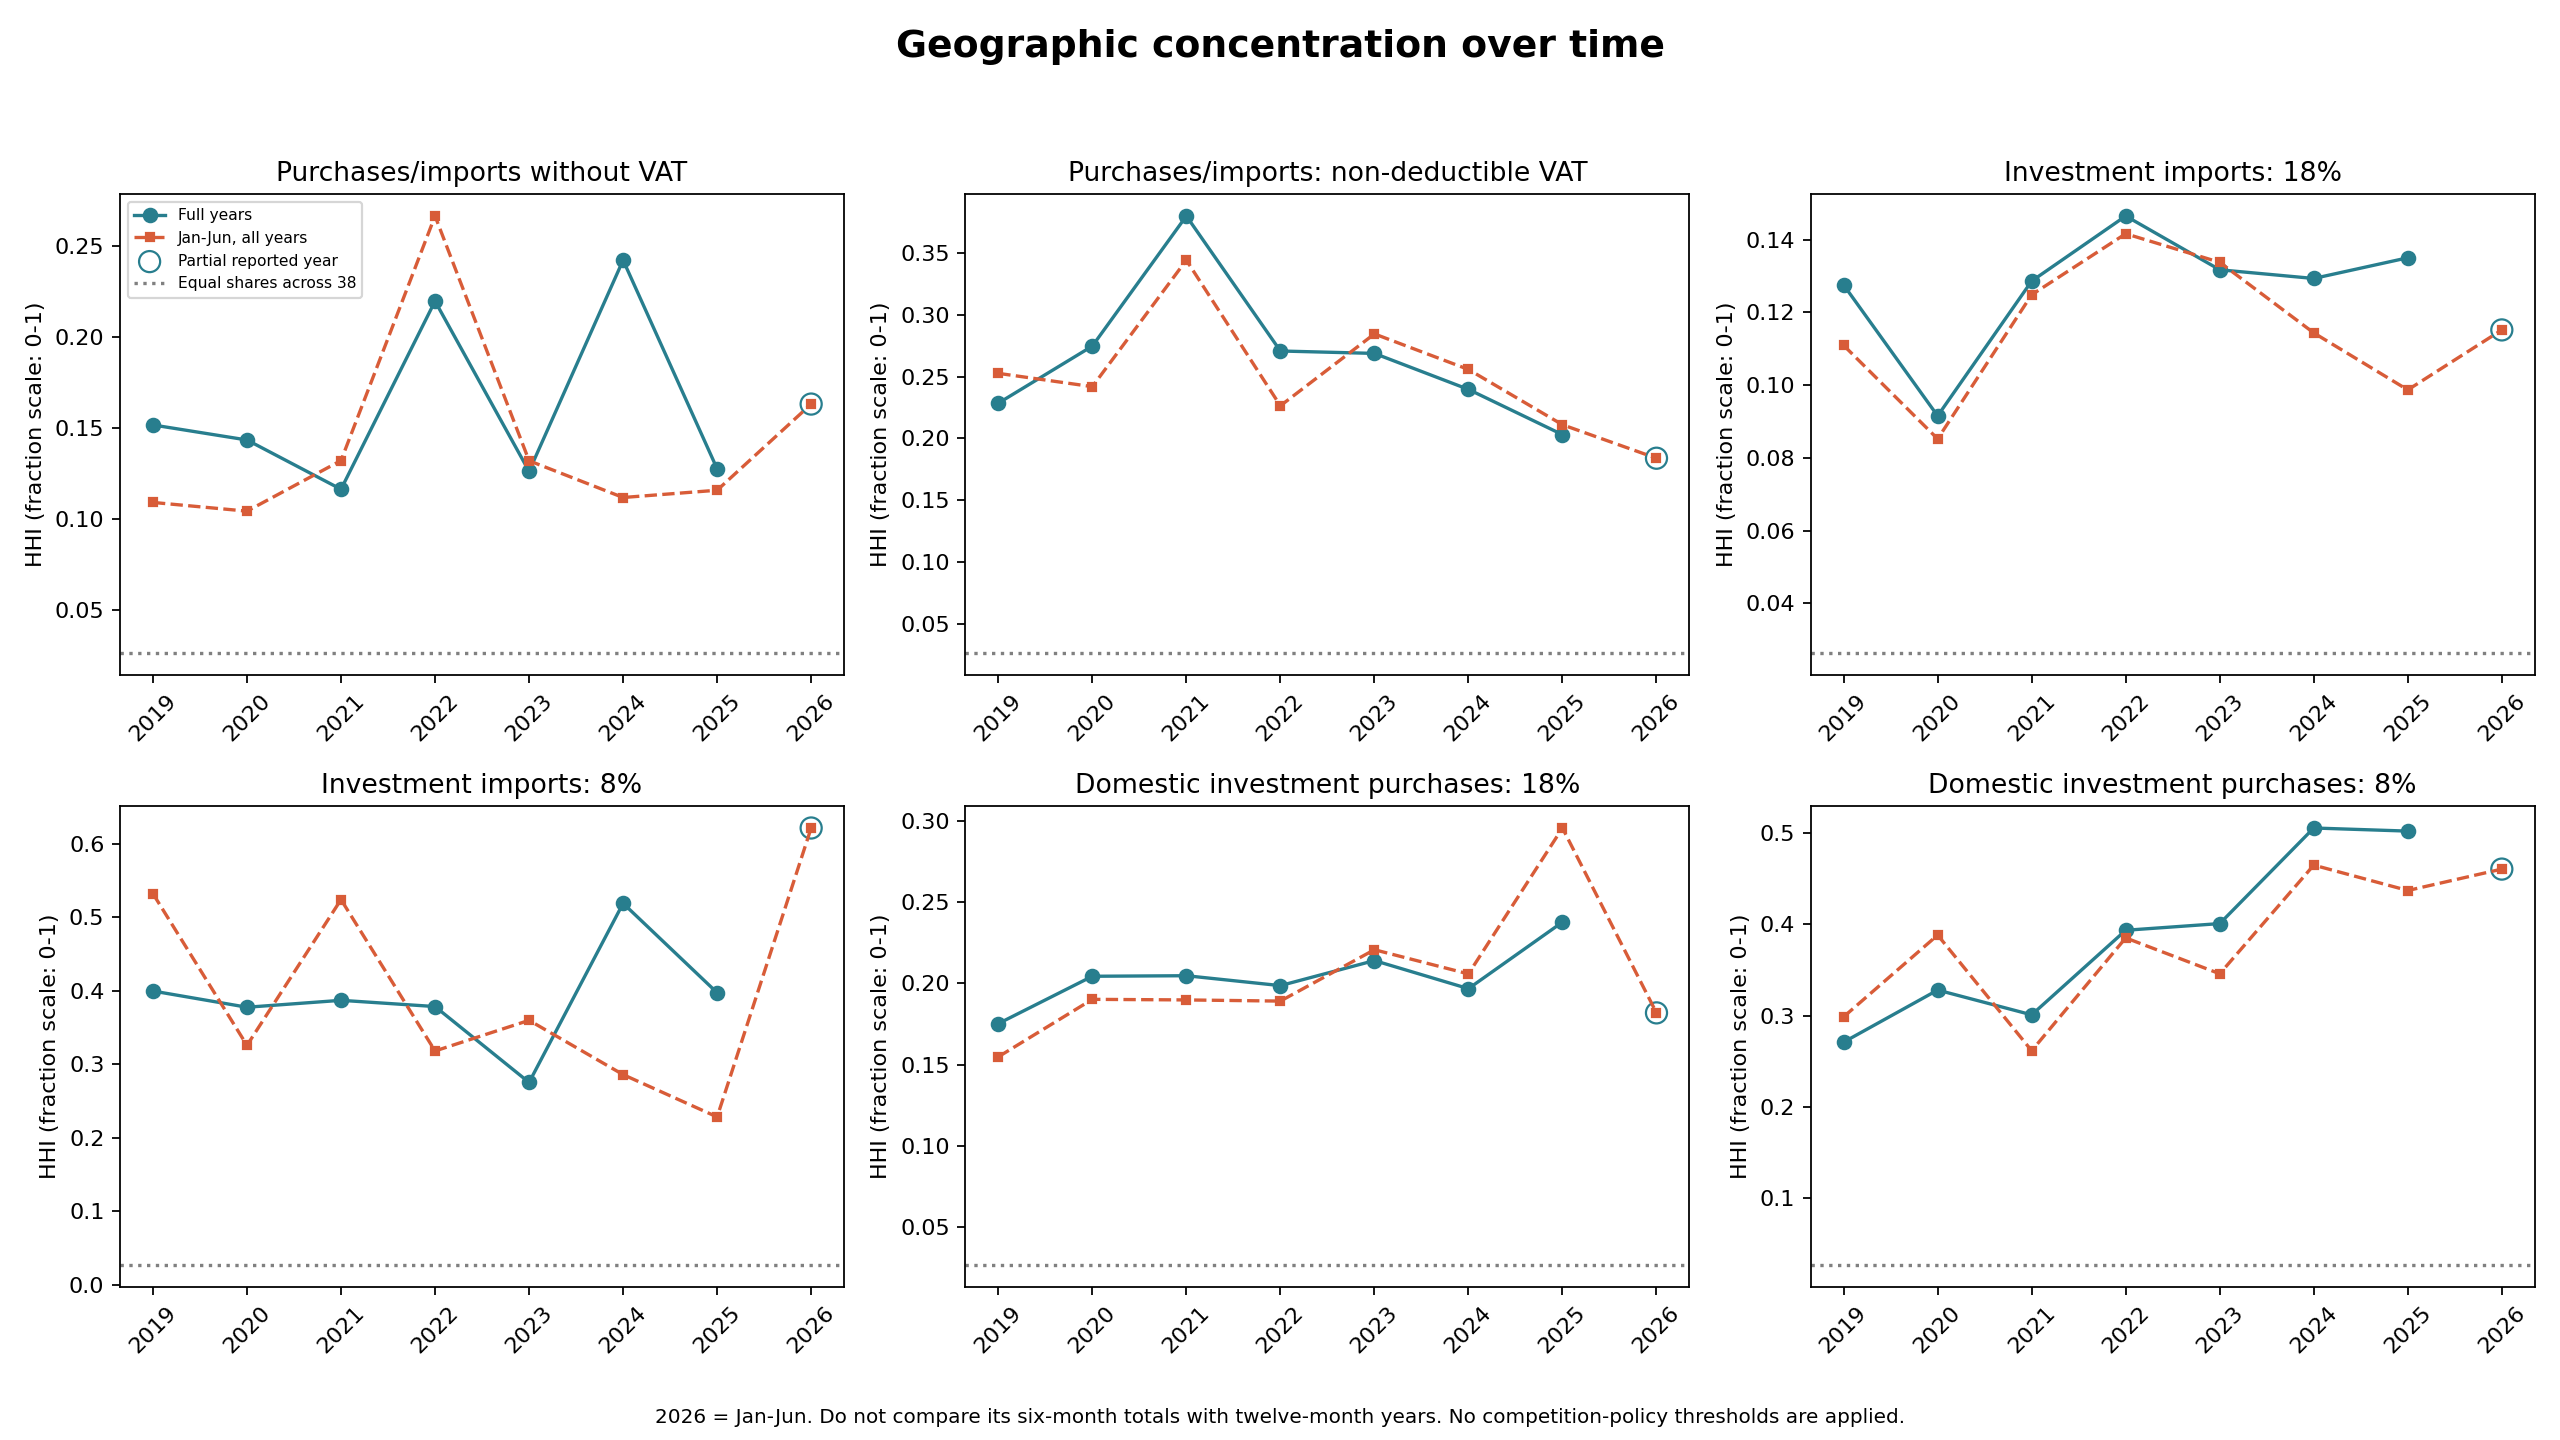

,year,hhi,effective_municipalities,top5_share
52,2019,0.1548,6.46,67.29%
58,2020,0.1902,5.26,69.43%
64,2021,0.1898,5.27,67.97%
70,2022,0.1891,5.29,72.60%
76,2023,0.2208,4.53,73.20%
82,2024,0.2059,4.86,66.88%
88,2025,0.2958,3.38,73.31%
94,2026,0.1818,5.50,64.44%


In [4]:
figure('03_hhi_evolution.png')
display(concentration.query('window == "jan_jun" and measure == @MEASURE')
    [['year','hhi','effective_municipalities','top5_share']].style.format(
        {'hhi':'{:.4f}','effective_municipalities':'{:.2f}','top5_share':'{:.2%}'}))

## 4. Sector Specialization: Location Quotient

$$
LQ_{m,s}=\frac{V_{m,s}/V_{m,eligible}}{V_s/V_{Kosovo,eligible}}
$$

LQ compares a sector's share within a municipality with its national share: **LQ > 1** means above-national relative weight; **LQ = 1** means equal weight.

`Mungon aktiviteti` (unavailable activity) and `Person Fizik` (ambiguous label) remain in geographic totals but are excluded from both LQ denominators. The coverage table shows the resulting analytical subset.

LQ is shown only where its validity conditions are met. Grey heatmap cells are undefined (NA), rather than zero specialization. Detailed validity rules are documented in the README.

The status table counts municipality–sector combinations for each monetary category in the latest complete year, not raw records. It explains undefined LQ values, including an entirely grey panel when a negative eligible net cell makes that category’s LQ unavailable under the pipeline rule.

In [5]:
lq_status_counts=(lq.query('window == "reported" and year == @YEAR')
    .groupby(['measure','lq_status']).size().unstack(fill_value=0)
    .reindex(MONEY,fill_value=0))
lq_status_counts.index=lq_status_counts.index.map(MEASURE_LABELS)
lq_status_counts=lq_status_counts.rename(columns={
    'valid':'Valid LQ',
    'negative_net_sector_cell':'Undefined: negative net cell',
    'zero_national_eligible_total':'Undefined: no national eligible value',
    'zero_municipal_eligible_total':'Undefined: no municipal eligible value',
    'zero_national_sector_total':'Undefined: no national sector value',
    'excluded_from_sector_analysis':'Excluded sector label'})
lq_status_counts.index.name='Monetary category'
lq_status_counts.columns.name='LQ status'
display(lq_status_counts)

LQ status,Excluded sector label,Undefined: negative net cell,Valid LQ,Undefined: no municipal eligible value,Undefined: no national sector value
Monetary category,,,,,
Purchases/imports without VAT,76,0,703,19,76
Purchases/imports: non-deductible VAT,76,798,0,0,0
Investment imports: 18%,76,0,722,0,76
Investment imports: 8%,76,0,594,90,114
Domestic investment purchases: 18%,76,0,703,19,76
Domestic investment purchases: 8%,76,0,665,57,76


,measure,eligible_value_share,unclassified_records,ambiguous_records
36,Purchases/imports without VAT,95.02%,944,341
37,Purchases/imports: non-deductible VAT,98.68%,944,341
38,Investment imports: 18%,94.22%,944,341
39,Investment imports: 8%,96.33%,944,341
40,Domestic investment purchases: 18%,96.29%,944,341
41,Domestic investment purchases: 8%,96.98%,944,341


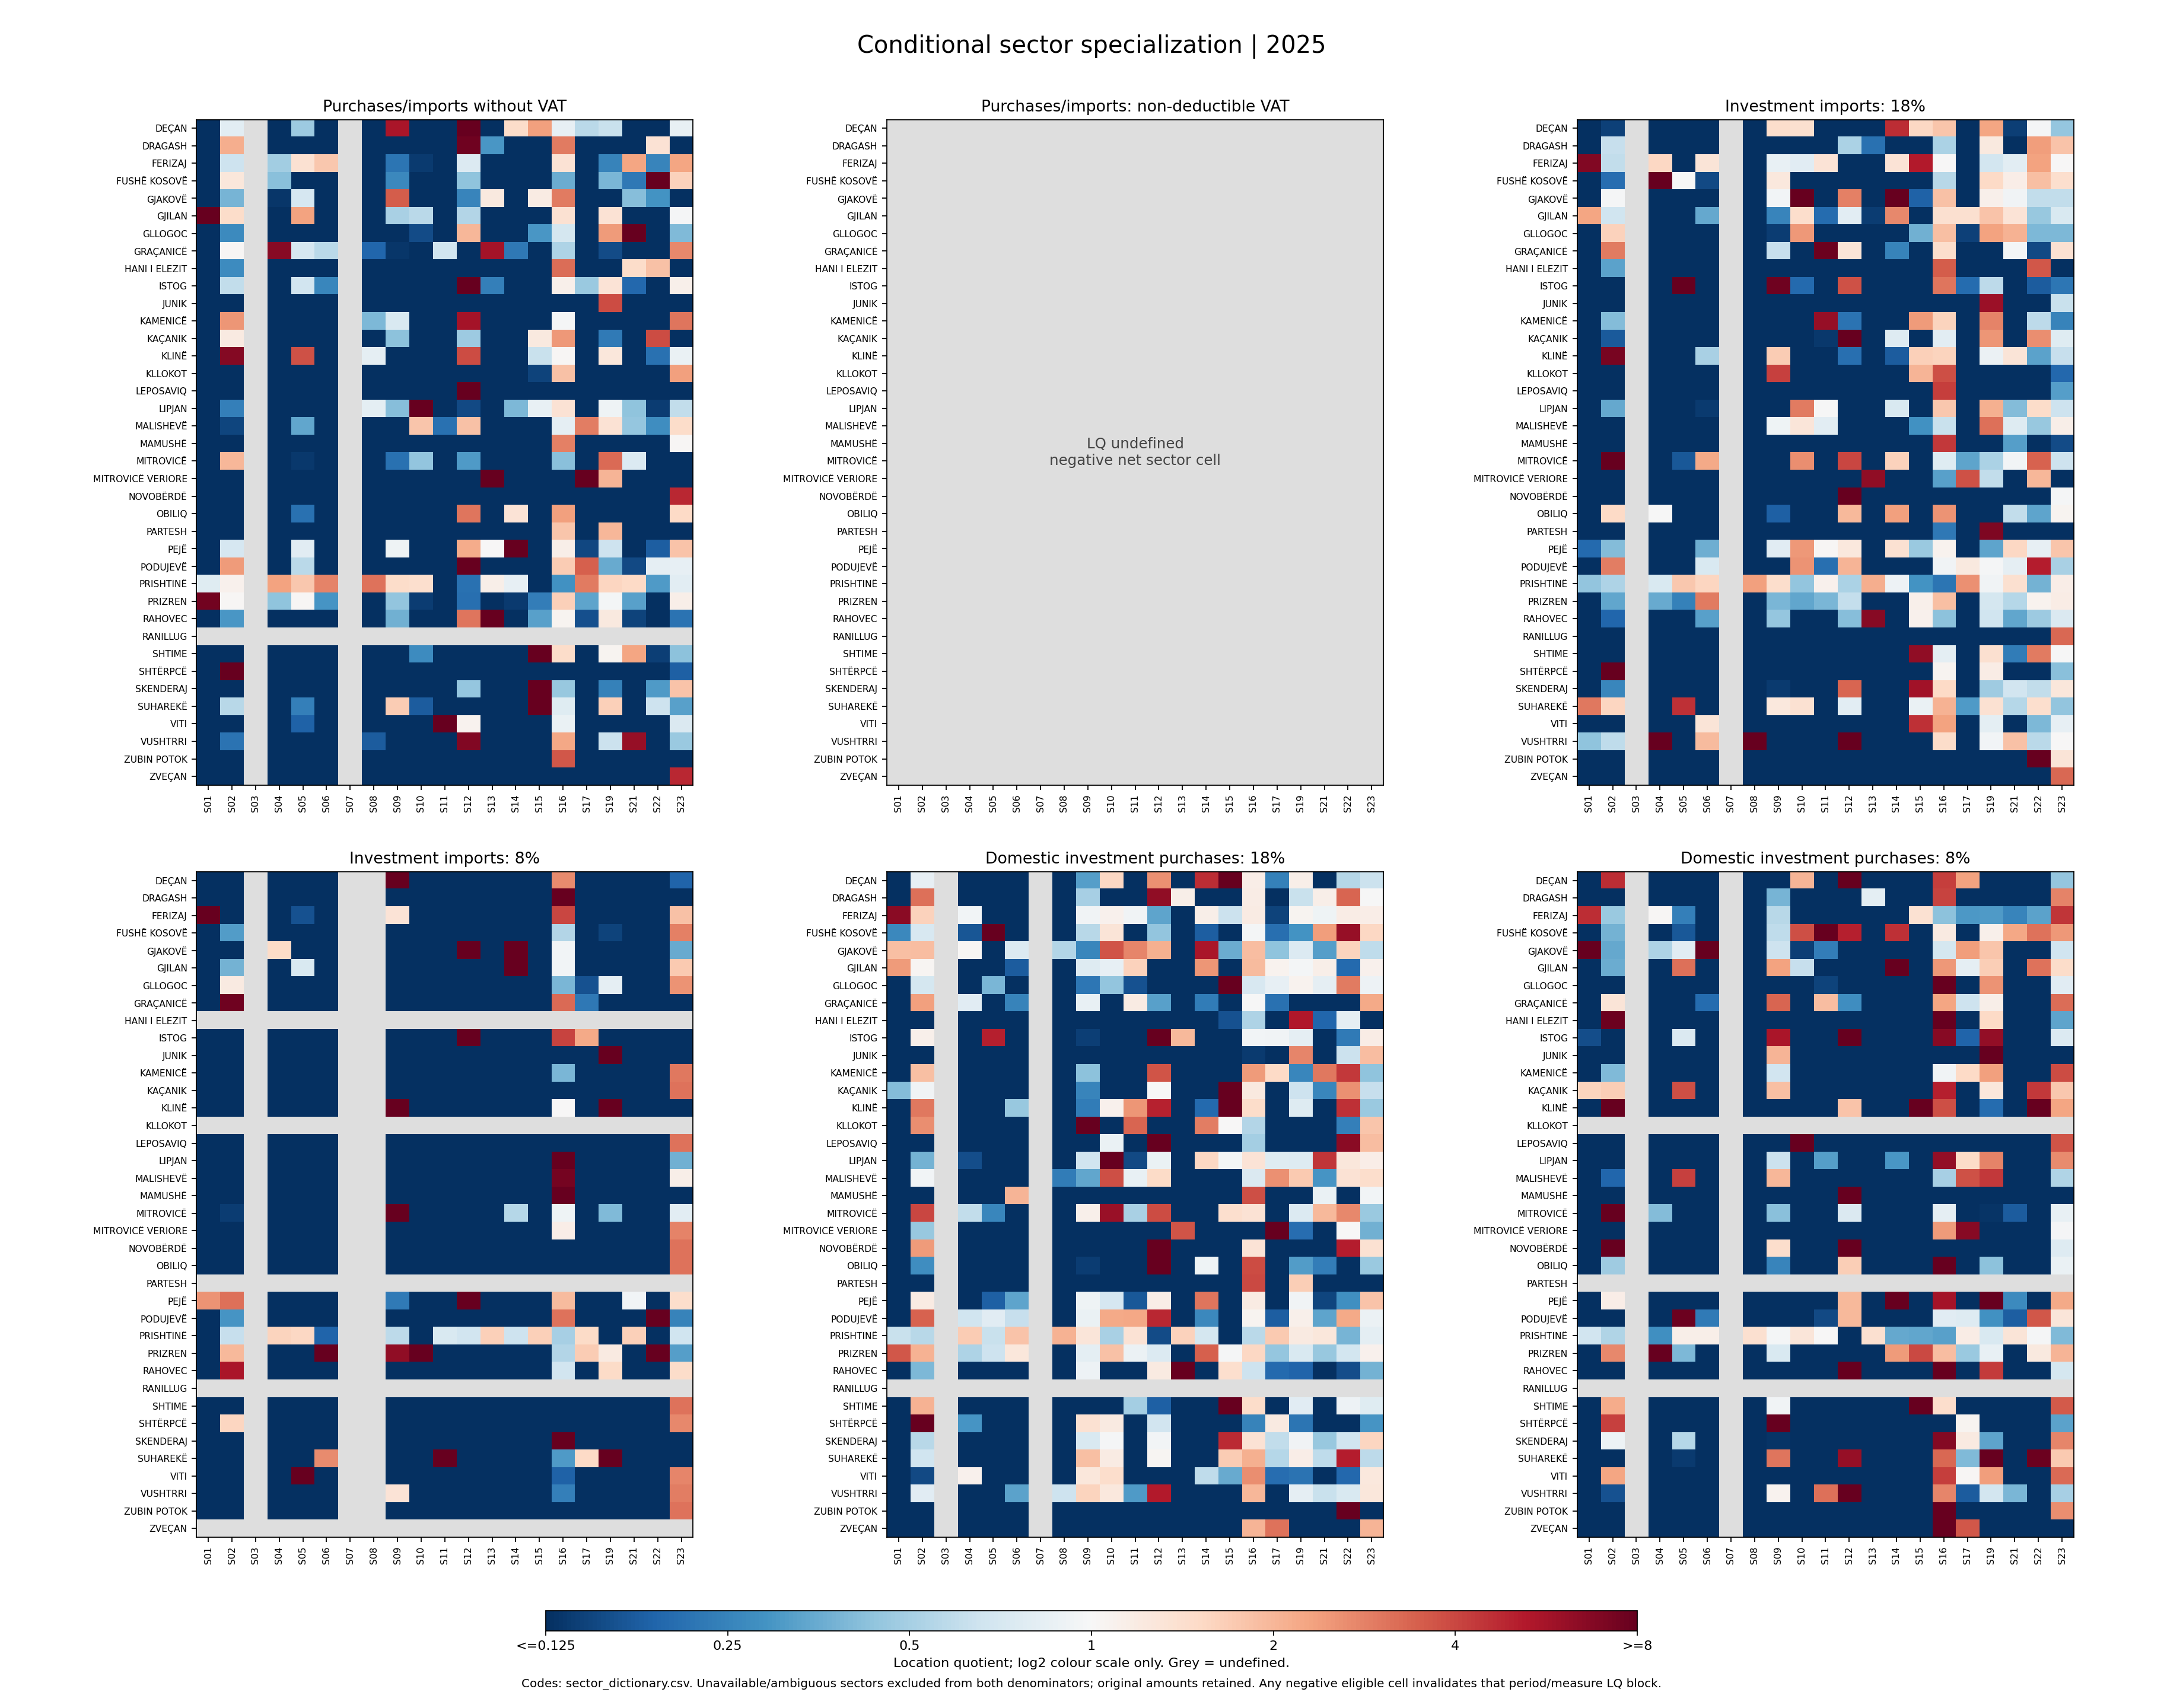

,sector_code,primary_sector
0,S01,Administrimi publik dhe mbrojtja; Sigurimi soc...
1,S02,Akomodimi dhe sherbimi ushqimor
2,S03,Aktivitetet e ekonomive familjare si punedhene...
3,S04,Aktivitetet e patundshmerise
4,S05,Aktivitetet e shendetit te njeriut dhe te pune...
5,S06,Aktivitetet e tjera sherbyese
6,S07,Aktivitetet e trupave dhe organizatave nderkom...
7,S08,Aktivitetet financiare dhe te sigurimit
8,S09,"Aktivitetet profesionale, shkencore dhe teknike"
9,S10,Arsimi


In [6]:
display(coverage.query('window == "reported" and year == @YEAR')
    [['measure','eligible_value_share','unclassified_records','ambiguous_records']]
    .assign(measure=lambda t:t.measure.map(MEASURE_LABELS)).style.format(
        {'eligible_value_share':'{:.2%}'}))
figure('04_sector_specialization.png')
dictionary=table('sector_dictionary')
display(dictionary.loc[dictionary.sector_eligible,['sector_code','primary_sector']])

## 5. Relative Specialization versus Absolute Value

A high LQ can arise from a small local amount or a rare national sector. Read it together with the cell amount and both denominators; high LQ alone does not imply a large national contribution.

In the scatter plot, colour represents **sector HHI within the municipality**: lower values indicate a more dispersed eligible-sector mix. This differs from geographic HHI, which measures concentration across municipalities.

,municipality,primary_sector,value,municipal_eligible_value,national_sector_value,location_quotient
5023,ZUBIN POTOK,Transporti dhe magazinimi,"41,101.69","42,632.58","19,415,788.58",43.35
4983,LEPOSAVIQ,Bujqesia;Pylltaria dhe Peshkimi,"20,289.32","74,623.95","6,156,775.96",38.55
4984,NOVOBËRDË,Bujqesia;Pylltaria dhe Peshkimi,"40,879.24","266,173.59","6,156,775.96",21.78
4998,KAÇANIK,Industria nxjerrese,"2,149,978.31","5,744,760.05","15,881,622.21",20.57
4985,ISTOG,Bujqesia;Pylltaria dhe Peshkimi,"1,037,033.14","7,834,658.42","6,156,775.96",18.77


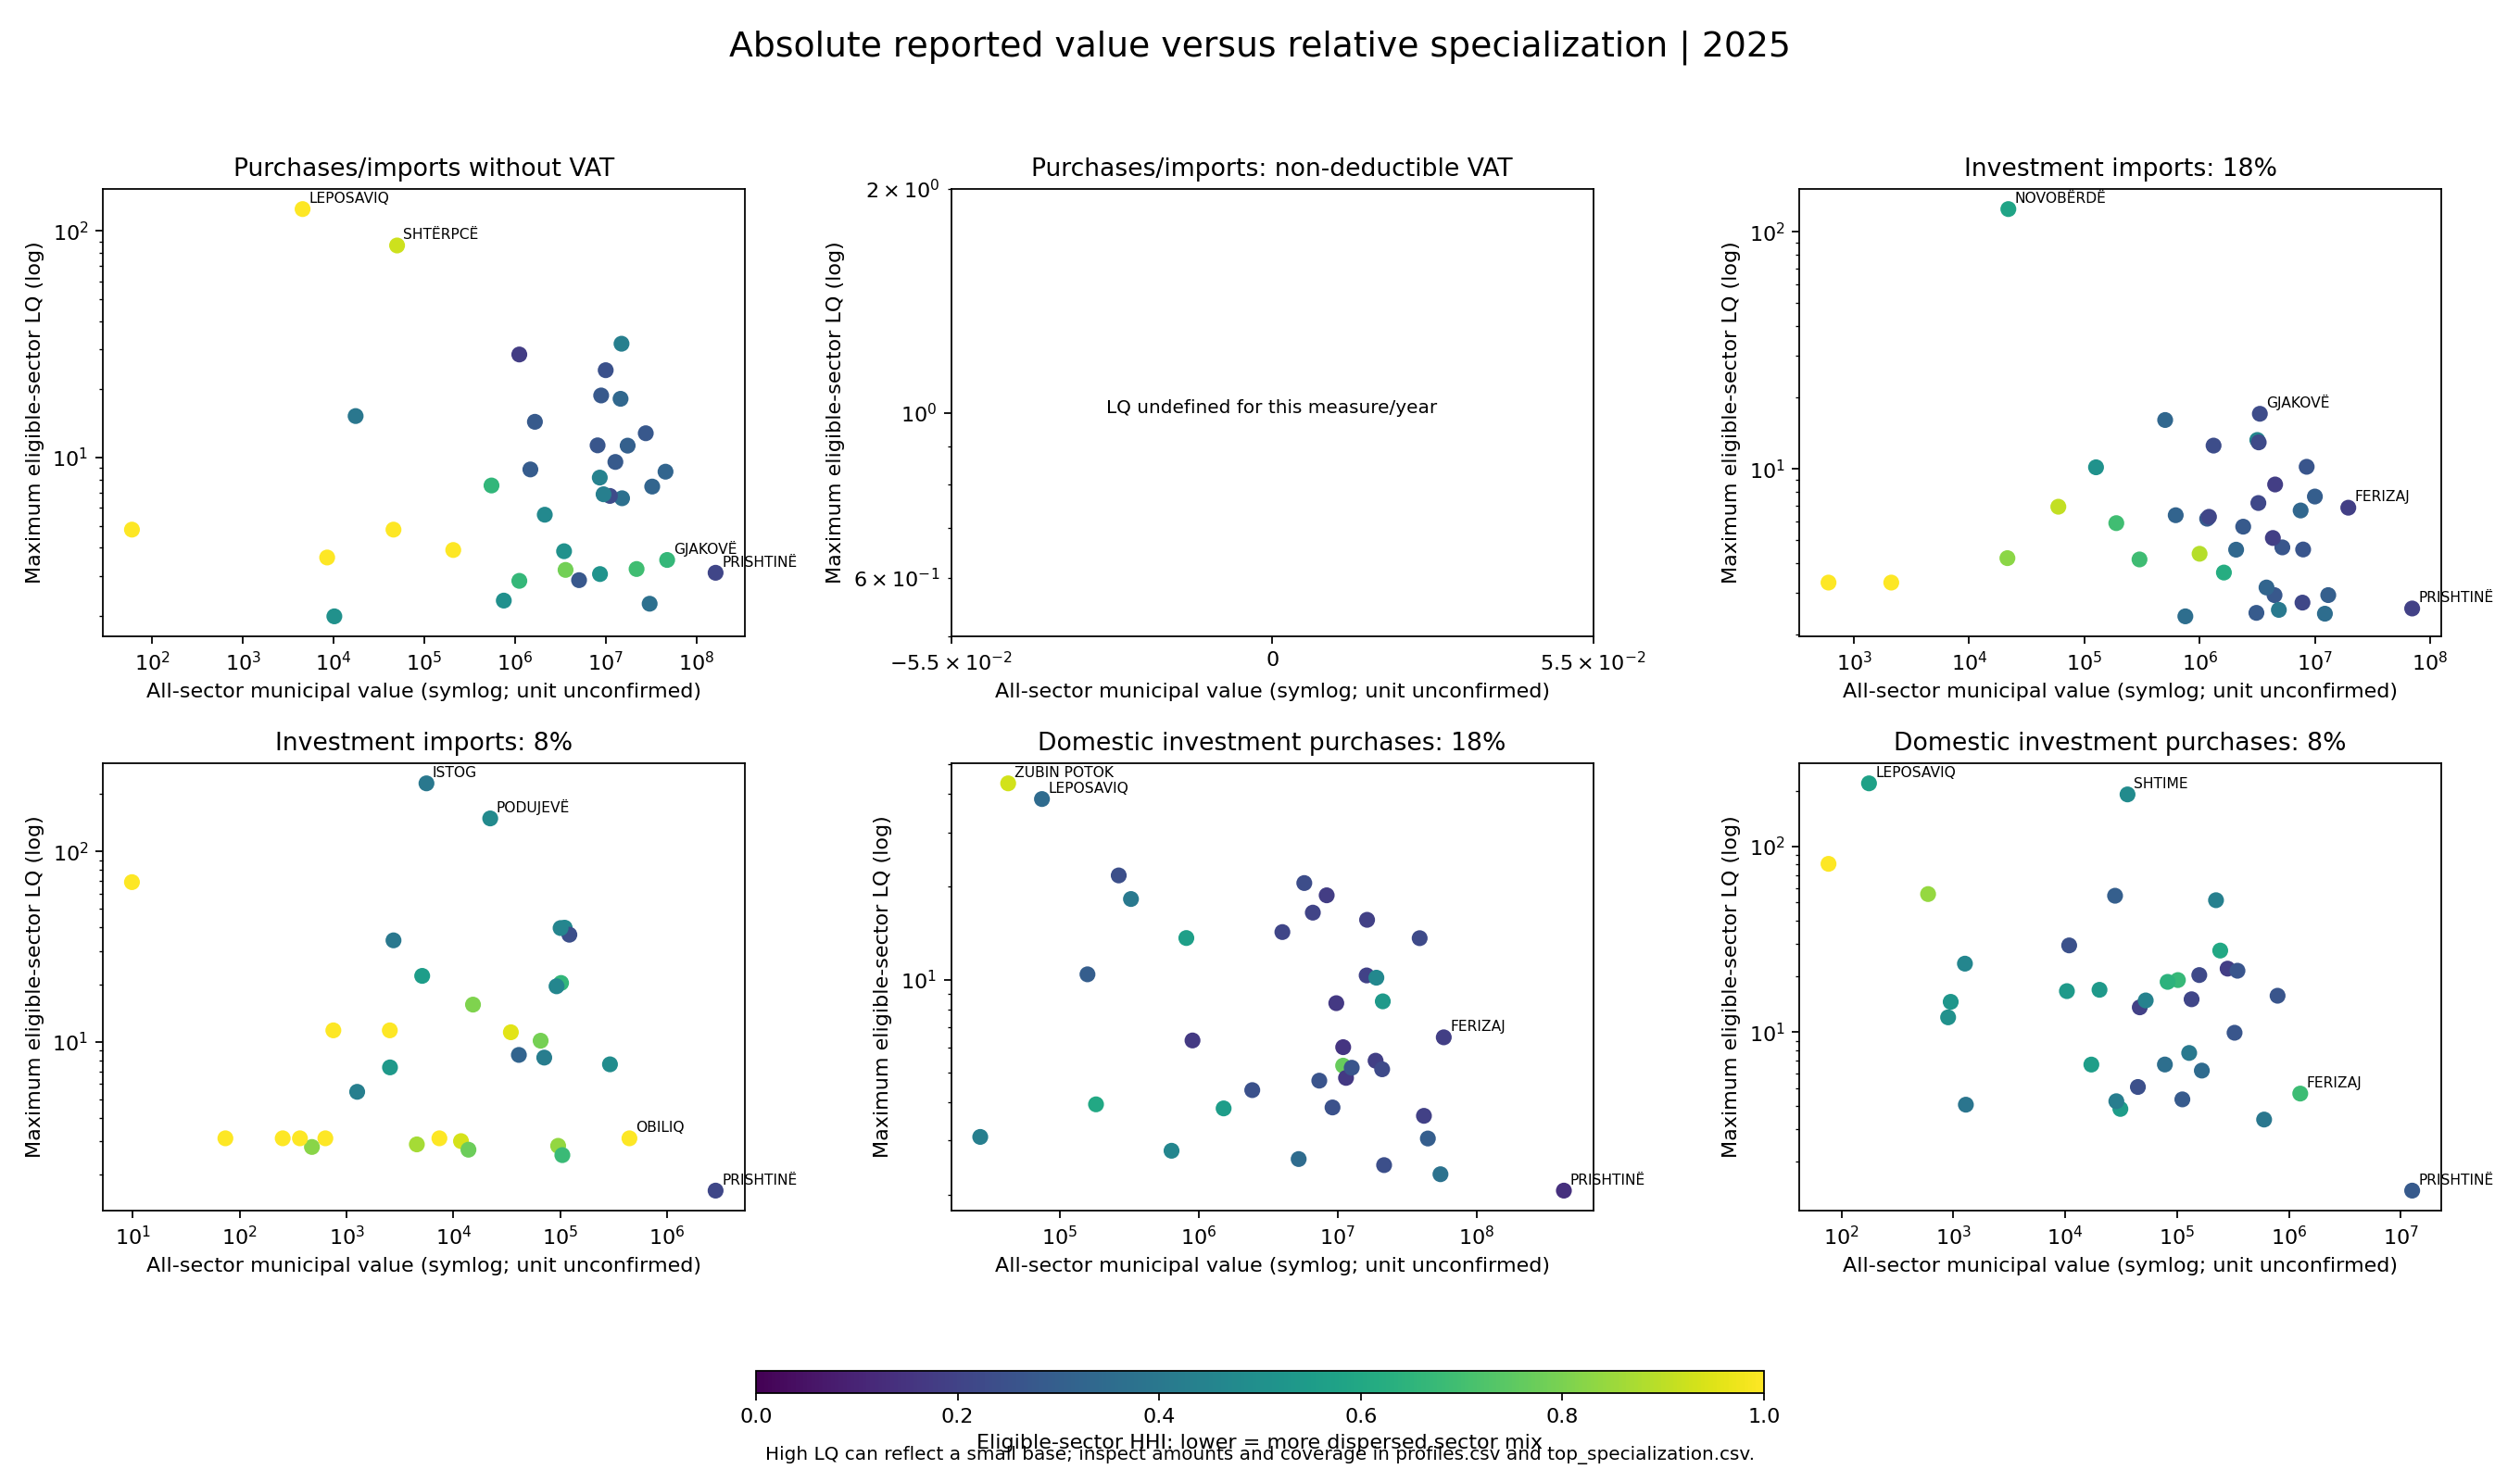

In [7]:
top=table('top_specialization')
display(top.query('window == "reported" and year == @YEAR and measure == @MEASURE')
    .nlargest(5,'location_quotient')
    [['municipality','primary_sector','value','municipal_eligible_value','national_sector_value','location_quotient']]
    .style.format({'value':'{:,.2f}','municipal_eligible_value':'{:,.2f}',
                   'national_sector_value':'{:,.2f}','location_quotient':'{:.2f}'}))
figure('05_municipal_profiles.png')

## 6. Descriptive Features and Visual Scales

- **Municipal share:** zero; low for 0 < share < 1%; medium for 1% ≤ share < 5%; high for share ≥5%. `top_contributor` flags shares ≥5%.
- **LQ:** ≤1; 1 < LQ ≤2; >2. `high_specialization` flags LQ >1, meaning above-national relative weight. Undefined flags remain NA.

These are descriptive thresholds, not official economic classifications. For heatmap colours only, LQ is clipped to [0.125, 8] before applying log2, giving a colour scale from -3 to 3. Exported LQ values remain unchanged. The scatter uses symlog for amounts and log for positive LQ to display skewed values.

In [8]:
display(focus[['municipality','municipal_share','share_band','top_contributor']]
    .head(5).style.format({'municipal_share':'{:.2%}'}))
municipality='PRISHTINË'
sector='Industria perpunuese'
display(lq.query('window == "jan_jun" and municipality == @municipality and primary_sector == @sector and measure == @MEASURE')
    [['year','location_quotient','lq_status']].style.format({'location_quotient':'{:.2f}'},na_rep='Undefined'))

,municipality,municipal_share,share_band,top_contributor
1520,PRISHTINË,46.83%,high,1
1521,FERIZAJ,6.40%,high,1
1522,GRAÇANICË,6.06%,high,1
1523,PEJË,4.92%,medium,0
1524,PRIZREN,4.61%,medium,0


,year,location_quotient,lq_status
46061,2019,0.28,valid
51305,2020,0.33,valid
56549,2021,0.35,valid
61793,2022,0.27,valid
67037,2023,0.29,valid
72281,2024,0.34,valid
77525,2025,0.70,valid
82769,2026,Undefined,negative_net_sector_cell


## 7. Sampling Sensitivity

Main conclusions use the full dataset. A reproducible 20% sample, stratified by year × municipality (`seed=42`), checks how sensitive HHI is to sampling.

Each sampled amount is weighted by **N/n**, where N is the stratum's population size and n its sample size. Large HHI differences indicate that this sample does not preserve the full distribution reliably. One sample does not provide a confidence interval.

In [9]:
sensitivity=table('sample_sensitivity')
display(sensitivity.assign(abs_hhi_difference=sensitivity.hhi_difference.abs())
    .nlargest(5,'abs_hhi_difference')
    [['window','year','measure','full_hhi','sampled_weighted_hhi','hhi_difference']]
    .assign(measure=lambda t:t.measure.map(MEASURE_LABELS)).style.format(
        {'full_hhi':'{:.4f}','sampled_weighted_hhi':'{:.4f}','hhi_difference':'{:.4f}'}))
print(f'Maximum absolute HHI difference: {sensitivity.hhi_difference.abs().max():.4f}')
print('Main conclusions use the full dataset.')

,window,year,measure,full_hhi,sampled_weighted_hhi,hhi_difference
87,jan_jun,2025,Investment imports: 8%,0.2281,0.7843,0.5562
33,reported,2024,Investment imports: 8%,0.5188,0.1719,-0.3468
45,reported,2026,Investment imports: 8%,0.6213,0.9256,0.3044
93,jan_jun,2026,Investment imports: 8%,0.6213,0.9256,0.3044
61,jan_jun,2021,Purchases/imports: non-deductible VAT,0.3441,0.6439,0.2998


Maximum absolute HHI difference: 0.5562
Main conclusions use the full dataset.


## 8. Validation and Interpretation

The 96 year × window × measure checks reconcile all aggregation levels with the input. Valid shares sum to 1; undefined indicators remain NA; input files are preserved.

Interpret results as **concentration and relative specialization of reported values**. LQ depends on the disclosed sector coverage, and large values can reflect small bases. The maps use static 2017 boundaries.

Methods: [BEA — LQ](https://www.bea.gov/help/faq/478), [DOJ — HHI formula](https://www.justice.gov/atr/herfindahl-hirschman-index), [geoBoundaries](https://www.geoboundaries.org/api.html).

In [10]:
validation=table('validation')
assert validation.status.eq('PASS').all()
for relative,sha in status['protected_input_hashes'].items():
    assert digest(root/relative)==sha
print(f"Validation: {len(validation)} checks passed; {status['map_matches']} municipality boundary matches.")
print(f"Records retained: {status['records']:,}; unavailable sector: {status['unclassified_records']:,}; ambiguous Person Fizik: {status['ambiguous_records']:,}.")
leader=focus.nlargest(1,'value').iloc[0]
print(f"In {YEAR}, {leader.municipality} represents {leader.municipal_share:.2%} of the focus measure.")
print(f"Across the six measures, geographic HHI ranges from {latest.hhi.min():.4f} to {latest.hhi.max():.4f} in {YEAR}.")

Validation: 96 checks passed; 38 municipality boundary matches.
Records retained: 124,262; unavailable sector: 4,484; ambiguous Person Fizik: 2,734.
In 2025, PRISHTINË represents 46.83% of the focus measure.
Across the six measures, geographic HHI ranges from 0.1277 to 0.5021 in 2025.
